In [33]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

In [58]:
# 도미 - 35
bream_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0, 32.0, 32.0, 33.0, 33.0, 33.5, 33.5, 34.0, 34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0]
bream_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0, 600.0, 600.0, 700.0, 700.0, 610.0, 650.0, 575.0, 685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0]
# 빙어  - 14
smelt_length = [9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
smelt_weight = [6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]
length = bream_length + smelt_length
weight = bream_weight + smelt_weight

In [59]:
data = np.column_stack((length,weight))
label = [1]*35 + [0]*14


In [39]:
data[0:2]

array([[ 25.4, 242. ],
       [ 26.3, 290. ]])

In [ ]:
# 데이터 전처리
# 표준점수 고려해야 함.
# 표준점수 = (특성값 - 산술평균) / 표준편차
mean = np.mean(data,axis=0) # 행의 기준으로 산술평균
std = np.std(data,axis=0)   # 행의 기준으로 표준편차
train_scaled = (data-mean)/std
new_data =([25,120]-mean)/std
new_data2 =([29.5,300]-mean)/std

In [49]:
train_data,test_data,train_label,test_label = train_test_split(train_scaled,label) #train_scaled(-1.5 - 1.5)

In [50]:
train_data

array([[-1.46532586, -1.33106482],
       [ 0.68505343,  0.7405068 ],
       [ 0.58641218,  0.78669225],
       [-0.07448421, -0.47571019],
       [ 0.3595373 ,  0.17088618],
       [-1.38641286, -1.33106482],
       [-1.62315187, -1.34707578],
       [ 0.78369468,  0.84827286],
       [-1.48505411, -1.33845449],
       [ 1.22758032,  1.47947408],
       [ 0.6357328 ,  0.63274074],
       [-0.16326134, -0.62350364],
       [-1.58369537, -1.33876239],
       [ 0.78369468,  0.78669225],
       [ 0.6357328 ,  0.50957952],
       [-1.18913036, -1.30735628],
       [-1.63301599, -1.34553626],
       [ 0.26089605,  0.01693467],
       [-1.50478237, -1.33783868],
       [ 0.38912967,  0.17088618],
       [-1.44559761, -1.32736998],
       [ 0.78369468,  0.86366801],
       [ 0.98097719,  1.71040136],
       [ 0.88233593,  0.82979868],
       [ 0.58641218,  0.78669225],
       [ 0.19184717, -0.25094097],
       [ 0.38912967,  0.09391043],
       [-1.70206487, -1.34799948],
       [-1.25817924,

In [53]:
clf = KNeighborsClassifier()
clf.fit(train_data,train_label)
result = clf.predict(test_data)
score = clf.score(test_data,test_label)
print('예측 : ',score)

예측 :  1.0


In [56]:
distances,indexes = clf.kneighbors([new_data])
indexes

array([[11,  3, 30, 25, 35]])

In [52]:

result1 = clf.predict([new_data2])
print("예측생선 : ",result1)
#단위를 표준점수로 맞춰줌.
result2 = clf.predict([new_data]) #빙어로 예측이 되었으나 , 표준점수를 적용후 도미로 예측됨.
print("예측생선 : ",result2)
# distances,indexes = clf.kneighbors([[25,120]])
# distances
# indexes

예측생선 :  [1]
예측생선 :  [1]


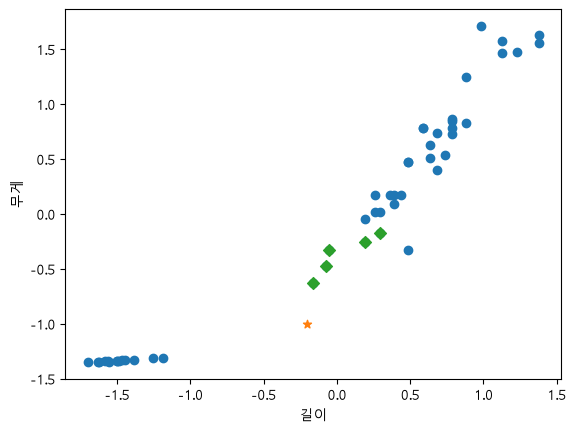

In [57]:
plt.scatter(train_scaled[:,0],train_scaled[:,1])
plt.scatter(new_data[0],new_data[1],marker='*')
plt. scatter(train_data[indexes,0],train_data[indexes,1],marker='D')
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()

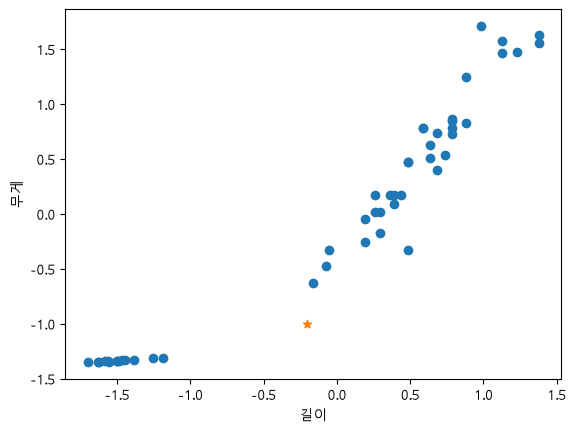

In [44]:
plt.scatter(train_scaled[:,0],train_scaled[:,1])
plt.scatter(new_data[0],new_data[1],marker='*')
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()

In [ ]:
train_data,test_data,train_label,test_label = train_test_split(data,label,stratify=label,test_size=0.2)

In [ ]:
length = bream_length + smelt_length
weight = bream_weight + smelt_weight
data = [[l,w] for l,w in zip(length,weight)]
label = [1]*35 + [0]*14
train_data,test_data,train_label,test_label = train_test_split(data,label,stratify=label,test_size=0.2)

In [10]:
clf = KNeighborsClassifier()
clf.fit(train_data,train_label)
result = clf.predict(test_data)
score = clf.score(test_data,test_label)
print('정답률 : ',score)

정답률 :  1.0


In [29]:
# data1 = input('길이,무게입력 : ')
# data1 = data1.split(' ')

# data2 = [float(x) for x in data1]
# result = clf.predict([data2])
result1 = clf.predict([[29.5,330]])
print("예측생선 : ",result1)
result2 = clf.predict([[25,150]])
print("예측생선 : ",result2)
distances,indexes = clf.kneighbors([[25,120]])
distances
indexes


# if result == 1:
#     print('도미')
# elif result == 0:
#     print('빙어')

예측생선 :  [1]
예측생선 :  [0]


array([[10,  0, 20, 36, 23]])

TypeError: list indices must be integers or slices, not tuple

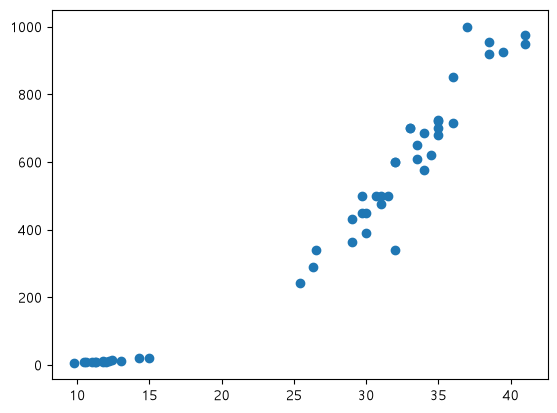

In [30]:
plt.scatter(length,weight)
# plt.scatter(bream_length,bream_weight)
plt. scatter(train_data[indexes,0],train_data[indexes,1],marker='D')
# plt.scatter(29.5,330,marker='^')
plt.scatter(25,150,marker='*')
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()